In [1]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt  
from sklearn.datasets import make_regression
import plotly.express as px
import plotly.graph_objects as go 
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score

In [2]:
x,y = make_regression(n_samples=200,n_features=2,n_targets=1,n_informative=2,noise=15)

In [3]:
df = pd.DataFrame({'feature1':x[:,0],'feature2':x[:,1],'target':y})

In [4]:
df.head()

,feature1,feature2,target
0,0.069910,1.186606,48.635028
1,-0.575256,-0.833331,-49.510594
2,-1.867776,-0.315224,-96.648120
3,-0.942185,-0.927310,-72.878024
4,0.680849,0.445934,39.795105


In [5]:
df.shape

(200, 3)

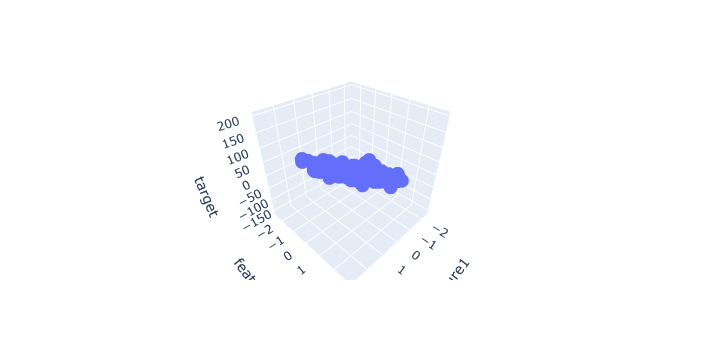

In [6]:

fig = px.scatter_3d(df, x='feature1', y='feature2', z='target')

fig.show()

In [7]:
x = df.iloc[:,0:2]
y = df.iloc[:,-1]

In [8]:
x.head()

,feature1,feature2
0,0.069910,1.186606
1,-0.575256,-0.833331
2,-1.867776,-0.315224
3,-0.942185,-0.927310
4,0.680849,0.445934


In [9]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=29)

In [10]:
from sklearn.linear_model import LinearRegression
lr = LinearRegression()

In [11]:
lr.fit(x_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [12]:
y_pred = lr.predict(x_test)

In [13]:
print("MAE : ",mean_absolute_error(y_test,y_pred))

MAE :  12.277747414699764


In [14]:
print("MSE : ",mean_squared_error(y_test,y_pred))

MSE :  227.46476348320365


In [15]:
print("r2 score : ",r2_score(y_test,y_pred))

r2 score :  0.9333989025523635


In [16]:
x = np.linspace(-5, 5, 10)
y = np.linspace(-5, 5, 10)
xGrid, yGrid = np.meshgrid(y, x)

final = np.vstack((xGrid.ravel().reshape(1, 100), yGrid.ravel().reshape(1, 100))).T

z_final = lr.predict(final).reshape(10, 10)
z = z_final

C:\Users\punee\anaconda3\envs\jupyter_env\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


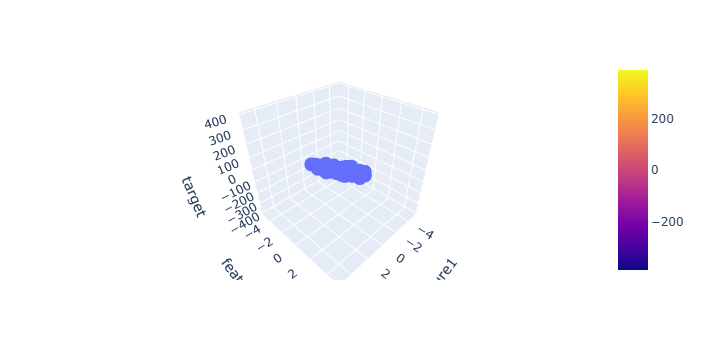

In [17]:

fig = px.scatter_3d(df, x='feature1', y='feature2', z='target')

fig.add_trace(go.Surface(x = x, y = y, z =z ))

fig.show()
     

In [18]:
lr.coef_

array([49.09662433, 28.60295676])

In [19]:
lr.intercept_

np.float64(-0.16199168567275857)

# Multiple Linear Regression from Scratch

In [20]:
class MeraLR:

    def __init__(self):
        self.coef_ = None
        self.intercept_ = None
    
    def fit(self,x_train,y_train): 
        x_train = np.insert(x_train,0,1,axis=1)
        
        # calcuate the coeffs
        betas = np.linalg.inv(np.dot(x_train.T,x_train)).dot(x_train.T).dot(y_train)
        self.intercept_ = betas[0]
        self.coef_ = betas[1:]

    def predict(self,x_test):
        y_pred = np.dot(x_test,self.coef_) + self.intercept_
        return y_pred

In [21]:
mlr = MeraLR()

In [22]:
mlr.fit(x_train,y_train)

In [23]:
y_pred1 = mlr.predict(x_test)

In [24]:
r2_score(y_test,y_pred1)

0.9333989025523634

In [25]:
mlr.coef_

array([49.09662433, 28.60295676])

In [26]:
mlr.coef_

array([49.09662433, 28.60295676])